<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 1 — Euler vs RK4: Which One Do You Trust?</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

**Nothing here is assessed.** Have a go, compare notes with those around you, and be ready to talk a facilitator through what you found (this is good practice for the in-class assessment sessions later in the course).

## Where this fits

Today's lecture showed you the update rules for Euler's method and the classic 4th-order
Runge–Kutta method (RK4). You now know *how* each one steps a state forward in time. _Which one should you trust, and when?_

Today we'll implement both and run them on a problem whose exact answer we know. 

## <span style="color:#B5121B">0. The problem: radioactive decay</span>

Radioactive decay has a known, exact solution:

$$\frac{dN}{dt} = -\lambda N, \qquad N(t) = N_0 e^{-\lambda t}$$

This cell sets up $N_0$, $\lambda$, and a Python function that describes the *exact* solution. This will give us a ground truth to compare against.

lambda = 0.8 /s, half-life = 0.866 s


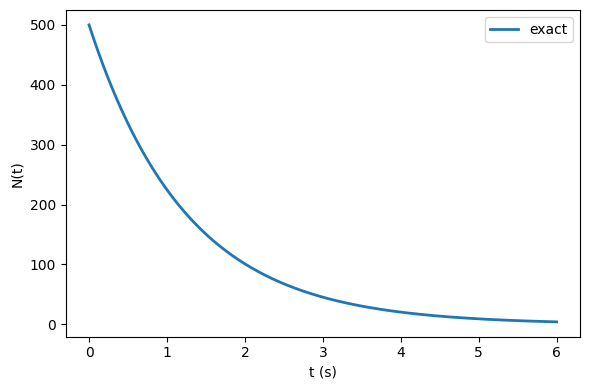

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N0 = 500.0      # initial quantity, arbitrary units
lam = 0.8       # decay constant, per second
half_life = np.log(2) / lam

print(f"lambda = {lam} /s, half-life = {half_life:.3f} s")


def N_exact(t, N0=N0, lam=lam):
    # The analytic solution -- our ground truth for everything below.
    return N0 * np.exp(-lam * t)


t_plot = np.linspace(0, 6, 400)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t_plot, N_exact(t_plot), lw=2, label="exact")
ax.set_xlabel("t (s)")
ax.set_ylabel("N(t)")
ax.legend()
fig.tight_layout()
plt.show()

## <span style="color:#B5121B">1. Implement Euler's method</span>

Recall the update rule from the lecture:

$$N_{i+1} = N_i + h \cdot f(t_i, N_i), \qquad f(t, N) = -\lambda N$$

Write a function that takes a step size `h` and a total time `t_max`, and returns arrays of `t` and `N` from $t=0$ to `t_max`, starting from `N0`.

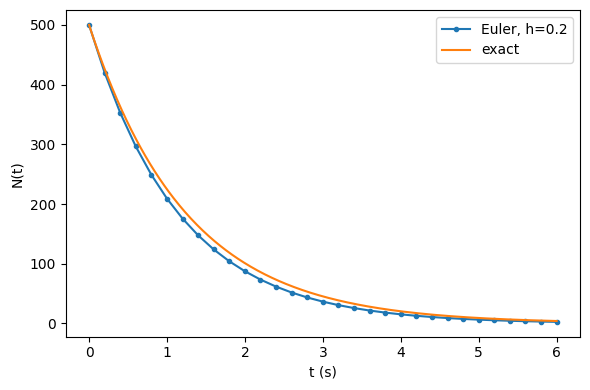

In [2]:
def f(t, N, lam=lam):
    # dN/dt, as a function of (t, N) -- the lecture's f(t, y)
    return -lam * N


def euler_integrate(h, t_max, N0=N0, lam=lam):
    n_steps = int(round(t_max / h))
    t = np.zeros(n_steps + 1)
    N = np.zeros(n_steps + 1)
    N[0] = N0

    for i in range(n_steps):
        t[i + 1] = t[i] + h
        N[i + 1] = N[i] + h * f(t[i], N[i], lam=lam)

    return t, N


t_e, N_e = euler_integrate(h=0.2, t_max=6)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t_e, N_e, "o-", ms=3, label="Euler, h=0.2")
ax.plot(t_plot, N_exact(t_plot), label="exact")
ax.legend(); ax.set_xlabel("t (s)"); ax.set_ylabel("N(t)")
fig.tight_layout()
plt.show()

## <span style="color:#B5121B">2. Implement RK4</span>

Same idea, but using the four-slope RK4 update from the lecture:

$$k_1 = f(t_i, N_i), \quad k_2 = f(t_i + h/2,\, N_i + \tfrac{h}{2}k_1), \quad
k_3 = f(t_i + h/2,\, N_i + \tfrac{h}{2}k_2), \quad k_4 = f(t_i + h,\, N_i + h k_3)$$
$$N_{i+1} = N_i + \frac{h}{6}(k_1 + 2k_2 + 2k_3 + k_4)$$

In [3]:
def rk4_integrate(h, t_max, N0=N0, lam=lam):
    n_steps = int(round(t_max / h))
    t = np.zeros(n_steps + 1)
    N = np.zeros(n_steps + 1)
    N[0] = N0

    for i in range(n_steps):
        k1 = f(t[i], N[i], lam=lam)
        k2 = f(t[i] + h / 2, N[i] + h / 2 * k1, lam=lam)
        k3 = f(t[i] + h / 2, N[i] + h / 2 * k2, lam=lam)
        k4 = f(t[i] + h, N[i] + h * k3, lam=lam)
        t[i + 1] = t[i] + h
        N[i + 1] = N[i] + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)

    return t, N


t_r, N_r = rk4_integrate(h=0.2, t_max=6)
print("RK4 defined OK, final value:", N_r[-1], "vs exact:", N_exact(6))

RK4 defined OK, final value: 4.114996811700365 vs exact: 4.114873524510012


## <span style="color:#B5121B">3. Round 1: same step size, head to head</span>

Run both methods with the **same, moderate** step size (`h = 0.2` s, `t_max = 6` s, about seven half-lives) and plot both against the exact solution on the same axes.

Can you tell the two methods apart by eye? If not, note that too: it tells you how large a difference has to be before it is visible.

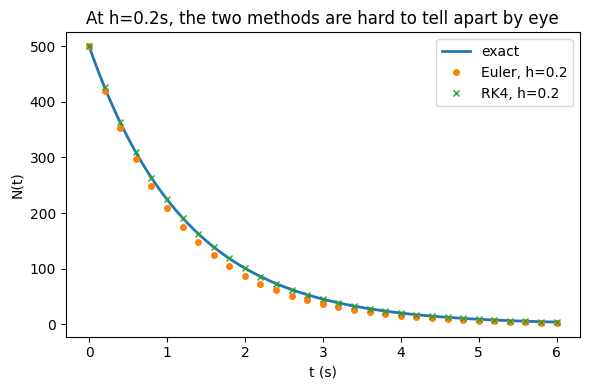

In [4]:
t_e, N_e = euler_integrate(h=0.2, t_max=6)
t_r, N_r = rk4_integrate(h=0.2, t_max=6)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t_plot, N_exact(t_plot), lw=2, label="exact")
ax.plot(t_e, N_e, "o", ms=4, label="Euler, h=0.2")
ax.plot(t_r, N_r, "x", ms=5, label="RK4, h=0.2")
ax.legend(); ax.set_xlabel("t (s)"); ax.set_ylabel("N(t)")
ax.set_title("At h=0.2s, the two methods are hard to tell apart by eye")
fig.tight_layout()
plt.show()

# Expected finding: at this step size both curves sit almost on top of the
# exact solution and on top of each other -- you cannot really tell them
# apart from the plot alone. That's the point of Section 4.

## <span style="color:#B5121B">4. Round 2: which one is closer?</span>

A plot only tells you so much. Compute the **error at the final time**, `abs(N_method[-1] - N_exact(t_max))`, for both methods at `h = 0.2`. Which is closer?

Repeat with a **coarser** step, `h = 1.0`. Does the gap between the methods grow or shrink as `h` increases? Can you explain this from the update rules?

In [5]:
for h in [0.2, 1.0]:
    t_e, N_e = euler_integrate(h=h, t_max=6)
    t_r, N_r = rk4_integrate(h=h, t_max=6)
    err_e = abs(N_e[-1] - N_exact(6))
    err_r = abs(N_r[-1] - N_exact(6))
    print(f"h={h:>4}: Euler error = {err_e:.6f}   RK4 error = {err_r:.2e}   "
          f"(RK4 is ~{err_e / err_r:,.0f}x closer)" if err_r > 0 else
          f"h={h:>4}: Euler error = {err_e:.6f}   RK4 error = {err_r:.2e}")

# Expected finding: RK4's error is already orders of magnitude smaller than
# Euler's at h=0.2, and the gap widens sharply at the coarser h=1.0 -- Euler's
# error grows much faster than RK4's as h increases.

h= 0.2: Euler error = 1.439721   RK4 error = 1.23e-04   (RK4 is ~11,678x closer)
h= 1.0: Euler error = 4.082874   RK4 error = 1.34e-01   (RK4 is ~30x closer)


<span style="color:#38614A">**Answer.**</span> At `h = 0.2` RK4's final-time error is about four orders of magnitude smaller than Euler's; at `h = 1.0` the ratio drops to ~30×. Both errors grow with `h`, RK4's much faster (a higher power of `h`), so the gap narrows as the step size increases.

## <span style="color:#B5121B">5. Round 3: how does the error scale with step size?</span>

Sweep `h` over several values (`h = 1.0, 0.5, 0.25, 0.125, 0.0625`), record the final-time error for each method, and plot **error against `h` on log-log axes**.

A straight line on a log-log plot means the error scales as a power of `h`, and the slope gives the power. This is the *convergence* from the lecture: compare the slopes for the two methods.

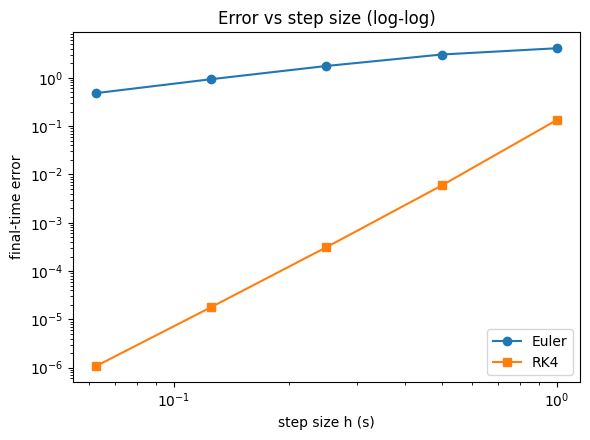

Euler slope ~ 0.79  (expected ~1, i.e. O(h))
RK4 slope   ~ 4.22  (expected ~4, i.e. O(h^4))


In [6]:
h_values = [1.0, 0.5, 0.25, 0.125, 0.0625]
euler_errors, rk4_errors = [], []

for h in h_values:
    _, N_e = euler_integrate(h=h, t_max=6)
    _, N_r = rk4_integrate(h=h, t_max=6)
    euler_errors.append(abs(N_e[-1] - N_exact(6)))
    rk4_errors.append(abs(N_r[-1] - N_exact(6)))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(h_values, euler_errors, "o-", label="Euler")
ax.loglog(h_values, rk4_errors, "s-", label="RK4")
ax.set_xlabel("step size h (s)")
ax.set_ylabel("final-time error")
ax.legend()
ax.set_title("Error vs step size (log-log)")
fig.tight_layout()
plt.show()

# Fitted slopes -- the convergence order for each method.
euler_slope = np.polyfit(np.log(h_values), np.log(euler_errors), 1)[0]
rk4_slope = np.polyfit(np.log(h_values), np.log(rk4_errors), 1)[0]
print(f"Euler slope ~ {euler_slope:.2f}  (expected ~1, i.e. O(h))")
print(f"RK4 slope   ~ {rk4_slope:.2f}  (expected ~4, i.e. O(h^4))")

# Expected finding: Euler's slope comes out close to 1 (first-order), RK4's
# comes out close to 4 (fourth-order) -- this is the measurable version of
# "RK4 is better," not just an impression from a plot.

<span style="color:#38614A">**Answer.**</span> The fitted slopes are about 0.8 for Euler and 4.2 for RK4: first- and fourth-order convergence (Euler's slope tends to 1 as `h` shrinks; the largest step sizes pull the fit down). Halving `h` halves Euler's error but cuts RK4's by ~16×.

## <span style="color:#B5121B">6. Round 4: break it</span>

Convergence is only half of the story. The other half is **stability**, also from the lecture. Forward Euler applied to this equation is only stable if $h < 2/\lambda$. With $\lambda = 0.8$/s, that is $h < 2.5$ s.

Try `h = 2.6` and `h = 4.0` for **both** methods, integrating to `t_max = 20` s, and plot the results.

What happens to Euler? This isn't a small numerical error: a quantity that should only decay starts to oscillate and grow. Does RK4 fail in the same way at these step sizes?

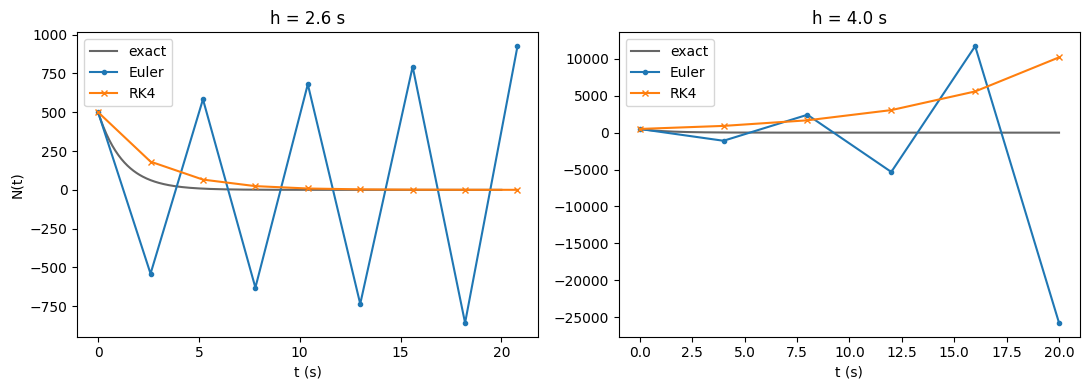

Euler's stability limit: h < 2.5 s
RK4's (real-axis) stability limit for this problem: h < 3.48 s


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, h in zip(axes, [2.6, 4.0]):
    t_e, N_e = euler_integrate(h=h, t_max=20)
    t_r, N_r = rk4_integrate(h=h, t_max=20)
    t_fine = np.linspace(0, 20, 400)
    ax.plot(t_fine, N_exact(t_fine), lw=1.5, color="k", alpha=0.6, label="exact")
    ax.plot(t_e, N_e, "o-", ms=3, label="Euler")
    ax.plot(t_r, N_r, "x-", ms=4, label="RK4")
    ax.set_title(f"h = {h} s")
    ax.set_xlabel("t (s)")
    ax.legend()

axes[0].set_ylabel("N(t)")
fig.tight_layout()
plt.show()

print("Euler's stability limit: h <", 2 / lam, "s")
print("RK4's (real-axis) stability limit for this problem: h <", round(2.785 / lam, 2), "s")

# Expected finding: at h=2.6s (just past Euler's 2.5s limit but well inside
# RK4's ~3.48s limit), Euler already oscillates with growing amplitude -- a
# supposedly-decaying quantity swinging through zero and growing in size --
# while RK4 still tracks the exact curve closely. At h=4.0s (past *both*
# methods' stability limits), RK4 also breaks down, but the story is still
# "RK4 tolerates a substantially larger step before failing," not "RK4 never
# fails" -- both methods have a stability limit, RK4's is just further out.

<span style="color:#38614A">**Answer.**</span> Above $h = 2/\lambda = 2.5$ s Euler's solution changes sign every step and grows in magnitude (each step multiplies $N$ by $1 - \lambda h < -1$). RK4 is still stable at `h = 2.6`: its limit for this equation is $h \approx 2.785/\lambda \approx 3.48$ s. At `h = 4.0` RK4 fails in the same way.

## The verdict: in your own words

Write two or three sentences in your logbook answering:

1. At a sensible step size, which method is more accurate, and by how much? (Use the power of `h` from Section 5, not just "RK4 is better".)
2. What goes wrong with Euler once `h` crosses the stability threshold? Is it a gradually growing error, or something more sudden?
3. Why might you still choose Euler over RK4? (Hint: how much does each step cost to compute?)

Be ready to explain your answers to a facilitator.

<span style="color:#38614A">**Answer.**</span> 1. RK4 is far more accurate at a sensible step size: error ∝ $h^4$ against ∝ $h$ for Euler.
2. Past the stability threshold Euler fails suddenly and qualitatively: a decaying, positive quantity oscillates in sign and grows. RK4 has a larger threshold (~3.48 s here) and fails the same way beyond it.
3. Euler costs one evaluation of $f$ per step against RK4's four, so when $f$ is expensive and the accuracy needed is modest, Euler at a small step can be the cheaper choice.

## Looking ahead to Exercise 1

Exercise 1 (25%, released after next week's lab) uses the same decay model, $N(t) = N_0 e^{-\lambda t}$, with noisy count data and two different techniques (root-finding and curve-fitting). As today, you will compare two methods: do they agree, and if not, why not?

## <span style="color:#FD9029">Extension (optional): a two-body orbit, and a look ahead to Kepler's equation</span>

You met this system in your Year 2 course: a body orbiting under an inverse-square force. The physics isn't new; the new part is comparing how Euler and RK4 handle it.

Unlike the decay problem, the position and velocity should trace out the same closed orbit forever. This gives a visual test: does the method stay on the orbit it started on?

### The physical setup (provided)

Units are chosen so that $GM = 1$. A body starting at $(x, y) = (1, 0)$ with velocity $(v_x, v_y) = (0, 1)$ moves on a circle of radius 1, with period $T = 2\pi$. The equations of motion are:

$$\dot{x} = v_x, \qquad \dot{y} = v_y, \qquad \dot{v}_x = -\frac{GM\,x}{r^3}, \qquad \dot{v}_y = -\frac{GM\,y}{r^3}, \qquad r = \sqrt{x^2 + y^2}$$

In [8]:
GM = 1.0
state0 = (1.0, 0.0, 0.0, 1.0)  # x, y, vx, vy -- a circular orbit, r=1, period 2*pi
T = 2 * np.pi


def orbit_accel(x, y, GM=GM):
    r3 = (x**2 + y**2) ** 1.5
    return -GM * x / r3, -GM * y / r3


def orbit_deriv(state, GM=GM):
    # state = (x, y, vx, vy) -- same idea as f(t, N) above, just a vector now.
    x, y, vx, vy = state
    ax, ay = orbit_accel(x, y, GM=GM)
    return np.array([vx, vy, ax, ay])

### Implement Euler and RK4 for the vector state

Same update rules as Sections 1–2, just applied to the 4-component state vector `(x, y, vx, vy)` instead of the single value `N`.

In [9]:
def euler_orbit(h, n_periods, state0=state0):
    n_steps = int(round(n_periods * T / h))
    states = np.zeros((n_steps + 1, 4))
    states[0] = state0
    for i in range(n_steps):
        states[i + 1] = states[i] + h * orbit_deriv(states[i])
    return states


def rk4_orbit(h, n_periods, state0=state0):
    n_steps = int(round(n_periods * T / h))
    states = np.zeros((n_steps + 1, 4))
    states[0] = state0
    for i in range(n_steps):
        k1 = orbit_deriv(states[i])
        k2 = orbit_deriv(states[i] + h / 2 * k1)
        k3 = orbit_deriv(states[i] + h / 2 * k2)
        k4 = orbit_deriv(states[i] + h * k3)
        states[i + 1] = states[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return states


e_states = euler_orbit(h=0.05, n_periods=5)
r_states = rk4_orbit(h=0.05, n_periods=5)
print("Euler final r:", np.hypot(e_states[-1, 0], e_states[-1, 1]))
print("RK4 final r:  ", np.hypot(r_states[-1, 0], r_states[-1, 1]))

Euler final r: 2.0136209556411178
RK4 final r:   0.9999997271751683


### Run it: does the orbit stay put?

Integrate both methods for 5 orbital periods at `h = 0.05` (about 126 steps per orbit, deliberately coarse). Plot:

1. the orbit in the $x$–$y$ plane for both methods on the same axes (use `ax.set_aspect("equal")` so that a circle looks circular);
2. the distance from the centre, $r(t) = \sqrt{x^2+y^2}$, against time for both methods. It should stay at $r=1$.

What does Euler's orbit do?

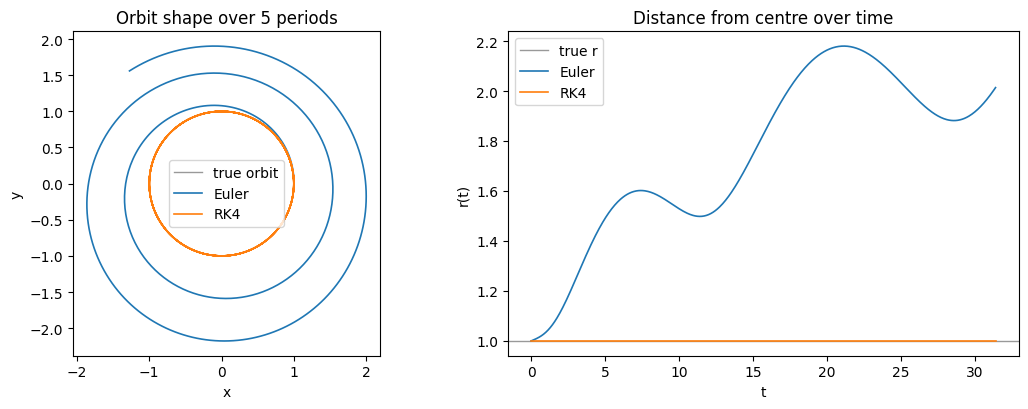

In [10]:
e_states = euler_orbit(h=0.05, n_periods=5)
r_states = rk4_orbit(h=0.05, n_periods=5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

theta = np.linspace(0, 2 * np.pi, 200)
axes[0].plot(np.cos(theta), np.sin(theta), color="k", lw=1, alpha=0.4, label="true orbit")
axes[0].plot(e_states[:, 0], e_states[:, 1], lw=1.2, label="Euler")
axes[0].plot(r_states[:, 0], r_states[:, 1], lw=1.2, label="RK4")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[0].set_title("Orbit shape over 5 periods")
axes[0].legend()

t_e = np.arange(len(e_states)) * 0.05
t_r = np.arange(len(r_states)) * 0.05
axes[1].axhline(1.0, color="k", lw=1, alpha=0.4, label="true r")
axes[1].plot(t_e, np.hypot(e_states[:, 0], e_states[:, 1]), lw=1.2, label="Euler")
axes[1].plot(t_r, np.hypot(r_states[:, 0], r_states[:, 1]), lw=1.2, label="RK4")
axes[1].set_xlabel("t"); axes[1].set_ylabel("r(t)")
axes[1].set_title("Distance from centre over time")
axes[1].legend()
fig.tight_layout()
plt.show()

# Expected finding: Euler's orbit visibly spirals outward -- r grows steadily with
# every period rather than staying at 1 -- while RK4's orbit stays essentially
# glued to the true circle over the same 5 periods. This isn't Euler being
# "somewhat less accurate": the orbit's whole qualitative character (closed,
# repeating) is wrong, because Euler doesn't conserve the orbit's energy the way
# the real system does -- it systematically adds energy every step.

### The verdict

1. What does Euler's orbit do over 5 periods? Does it just become *less accurate*, as in the decay problem, or does it fail in a different way?
2. Try a smaller step size (`h = 0.01`). Does Euler's problem go away, or just take longer to appear?
3. Why might an error in the *shape* of a solution (an orbit spiralling outward, energy not conserved) matter more in some applications than an error in its *size* (a slightly wrong decay curve)?

<span style="color:#38614A">**Answer.**</span> 1. Euler's orbit spirals outward (final $r \approx 2$ after 5 periods at `h = 0.05`) while RK4 stays on $r = 1$. This is a different kind of failure from the decay problem: energy isn't conserved, so the error builds up every orbit.
2. A smaller step slows the drift but doesn't remove it: at `h = 0.01`, $r \approx 1.45$ after 5 periods. There is no sharp threshold here, just a steady systematic drift.
3. A drift in shape keeps growing: after 50 periods at `h = 0.05`, Euler's orbit has reached $r \approx 4.7$ while RK4's is still at $r = 1.000$. For long simulations (planetary orbits, molecular dynamics) this matters far more than a small error in size.

### Looking ahead to Week 2

Here the orbit is found by stepping through time. For this problem there is also a direct relation between time and position, **Kepler's equation**, $M = E - e\sin E$, where $M$ is proportional to time and the eccentric anomaly $E$ gives the position. It can't be rearranged for $E$, so it has to be solved numerically: this is Week 2's root-finding example.

*(Optional stretch: the orbit above is circular, $e=0$. Try `state0 = (1.0, 0.0, 0.0, 0.7)` for an eccentric orbit. Does Euler do better or worse?)*

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>